# Admission Mortality - ICU

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import polars as pl
import numpy as np

from ethos.constants import PROJECT_ROOT
from ethos.constants import SpecialToken as ST
from ethos.inference.constants import Reason, Task
from ethos.metrics import compute_and_print_metrics, preprocess_inference_results

In [2]:
results_dir = PROJECT_ROOT / "results"
icu_mort_result_dir = results_dir / Task.ICU_MORTALITY
    
def process_icu_mortality_results(input_dir, outcome_tokens) -> pl.DataFrame:
    return preprocess_inference_results(
        input_dir,
        actual_expr=pl.col("actual").is_in(outcome_tokens),
        expected_expr=pl.col("expected").is_in(outcome_tokens),
        filter_ambiguous=(
            pl.col("actual").is_in([ST.DEATH, ST.ICU_DISCHARGE])
            & (pl.col("stop_reason") == Reason.GOT_TOKEN)
        ),
    )

2026-10-30 11:51:09.188 | WARNING  | ethos.metrics:preprocess_inference_results:323 - Dropped 2,202 (1.00%) ambiguous results.


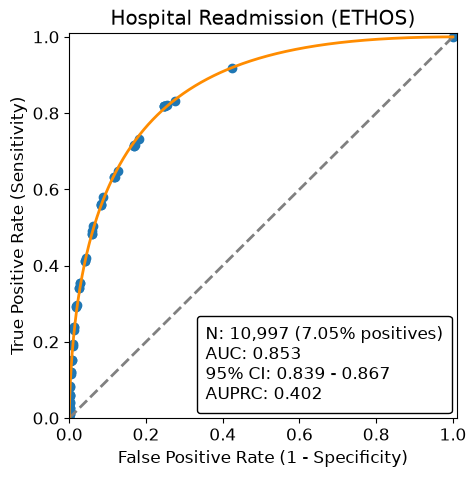

In [3]:
for input_dir in (results_dir / Task.ICU_MORTALITY).iterdir():
    df = process_icu_mortality_results(input_dir, outcome_tokens=[ST.DEATH])

    results = compute_and_print_metrics(
        df["expected"].to_numpy(),
        df["actual"].to_numpy(),
        figure_title="Hospital Readmission (ETHOS)",
    )

In [4]:
metrics = ["accuracy", "sensitivity", "specificity", "precision", "tp", "tn", "fp", "fn"]
for metric in metrics:
    res = results[metric]
    if type(res) is np.float64:
        print(f"{metric}: {res:.3f}")
    else:
        print(f"{metric}: {res}")

accuracy: 0.757
sensitivity: 0.819
specificity: 0.752
precision: 0.201
tp: 635
tn: 7692
fp: 2530
fn: 140
